In [4]:
import pandas as pd

# Baca data mentah
df_raw = pd.read_excel("BigDataset_dki_jakarta_2021_2025.xlsx")

In [5]:
# Ukuran tabel dan 20 baris terakhir
print(df_raw.shape)
df_raw.tail(20)

(42, 8)


,tahun,wilayah,rata_rata_lama_sekolah_tahun,tpt_laki_laki,tpt_perempuan,tpt_jumlah,p0_persentase_penduduk_miskin,p1_indeks_kedalaman_kemiskinan
22,2024,Jakarta Barat,11.24,6.01,6.46,6.18,3.94,0.26
23,2024,Jakarta Utara,10.85,5.79,6.82,6.18,6.44,1.01
24,2025,Kepulauan Seribu,9.27,6.90,8.82,7.71,12.37,1.95
25,2025,Jakarta Selatan,12.06,6.66,2.65,5.09,3.23,0.51
26,2025,Jakarta Timur,12.01,6.27,7.56,6.78,3.94,0.37
27,2025,Jakarta Pusat,11.62,6.39,5.61,6.09,4.70,0.60
28,2025,Jakarta Barat,11.25,6.00,6.06,6.02,3.91,0.68
29,2025,Jakarta Utara,11.08,5.77,6.42,6.02,6.33,0.99
30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,# Sumber: BPS - [Metode Baru] Rata-rata Lama S...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Tipe data tiap kolom
df_raw.dtypes

tahun                              object
wilayah                               str
rata_rata_lama_sekolah_tahun      float64
tpt_laki_laki                     float64
tpt_perempuan                     float64
tpt_jumlah                        float64
p0_persentase_penduduk_miskin     float64
p1_indeks_kedalaman_kemiskinan    float64
dtype: object

In [7]:
# Buang baris kosong/komentar (wilayah kosong), ubah tahun ke angka
df = df_raw.dropna(subset=["wilayah"]).copy()
df["tahun"] = df["tahun"].astype(int)

In [8]:
print(df.shape)
print(df.dtypes)
print(df["wilayah"].value_counts())
print(df["tahun"].value_counts().sort_index())

(30, 8)
tahun                               int64
wilayah                               str
rata_rata_lama_sekolah_tahun      float64
tpt_laki_laki                     float64
tpt_perempuan                     float64
tpt_jumlah                        float64
p0_persentase_penduduk_miskin     float64
p1_indeks_kedalaman_kemiskinan    float64
dtype: object
wilayah
Kepulauan Seribu    5
Jakarta Selatan     5
Jakarta Timur       5
Jakarta Pusat       5
Jakarta Barat       5
Jakarta Utara       5
Name: count, dtype: int64
tahun
2021    6
2022    6
2023    6
2024    6
2025    6
Name: count, dtype: int64


In [9]:
# Cek missing value dan duplikat kunci
print(df.isna().sum())
print(df.duplicated(subset=["tahun", "wilayah"]).sum())

tahun                             0
wilayah                           0
rata_rata_lama_sekolah_tahun      0
tpt_laki_laki                     0
tpt_perempuan                     0
tpt_jumlah                        0
p0_persentase_penduduk_miskin     0
p1_indeks_kedalaman_kemiskinan    0
dtype: int64
0


In [10]:
# Kolom numerik yang dianalisis
kolom = [
    "rata_rata_lama_sekolah_tahun",
    "tpt_laki_laki",
    "tpt_perempuan",
    "tpt_jumlah",
    "p0_persentase_penduduk_miskin",
    "p1_indeks_kedalaman_kemiskinan",
]

df[kolom].describe().round(2)

,rata_rata_lama_sekolah_tahun,tpt_laki_laki,tpt_perempuan,tpt_jumlah,p0_persentase_penduduk_miskin,p1_indeks_kedalaman_kemiskinan
count,30.00,30.00,30.00,30.00,30.00,30.00
mean,11.05,7.38,6.47,7.04,6.11,0.83
std,0.98,1.46,2.01,1.22,3.58,0.53
min,8.81,5.05,2.65,5.09,3.03,0.26
25%,10.82,6.39,4.87,6.11,3.98,0.56
50%,11.32,6.93,6.44,7.00,4.47,0.66
75%,11.67,8.09,7.90,8.01,6.70,1.00
max,12.06,10.93,10.59,9.84,15.06,2.61


In [11]:
# Kemiringan dan kurtosis
print(df[kolom].skew().round(2))
print(df[kolom].kurt().round(2))

rata_rata_lama_sekolah_tahun     -1.32
tpt_laki_laki                     0.88
tpt_perempuan                     0.04
tpt_jumlah                        0.34
p0_persentase_penduduk_miskin     1.57
p1_indeks_kedalaman_kemiskinan    1.81
dtype: float64
rata_rata_lama_sekolah_tahun      0.60
tpt_laki_laki                     0.28
tpt_perempuan                    -0.57
tpt_jumlah                       -0.61
p0_persentase_penduduk_miskin     1.11
p1_indeks_kedalaman_kemiskinan    3.51
dtype: float64


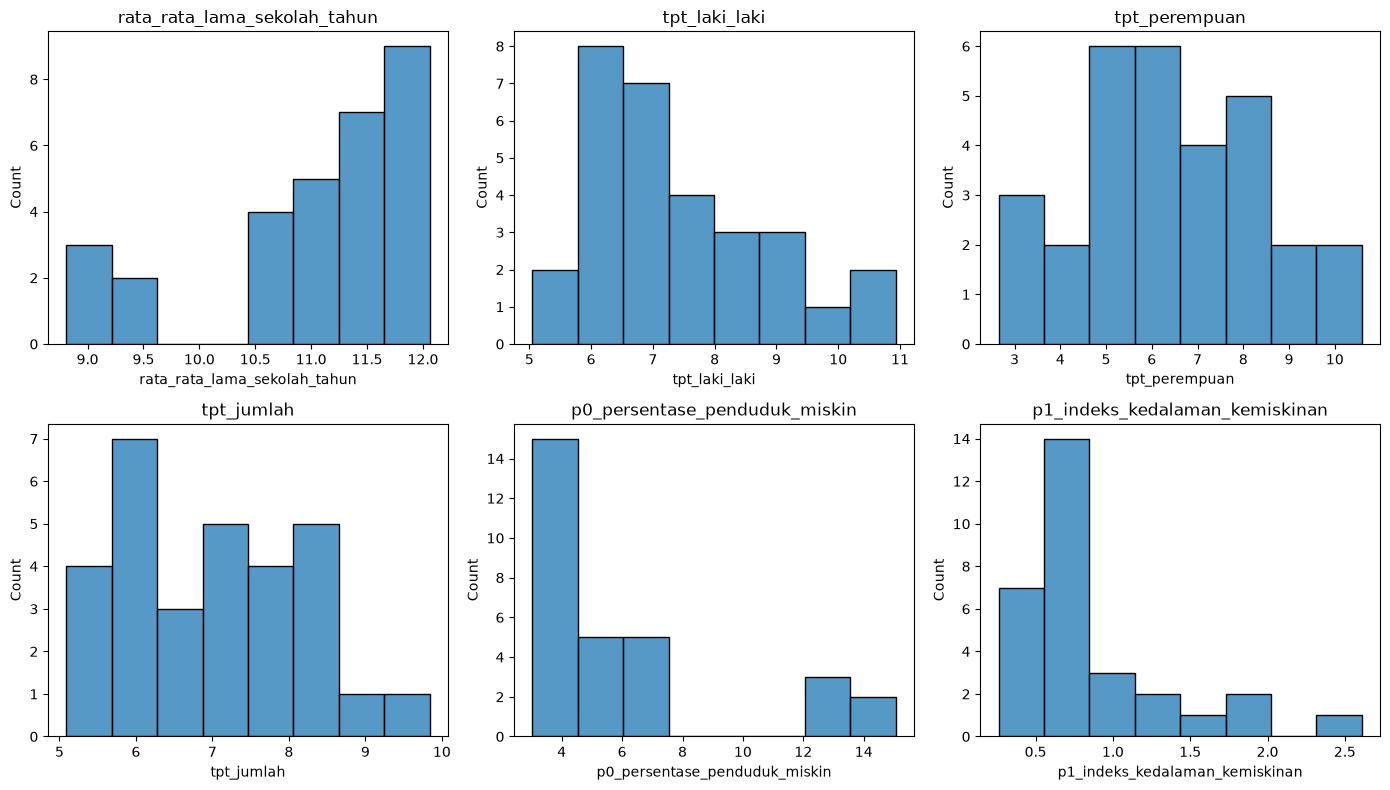

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, kolom):
    sns.histplot(df[col], bins=8, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

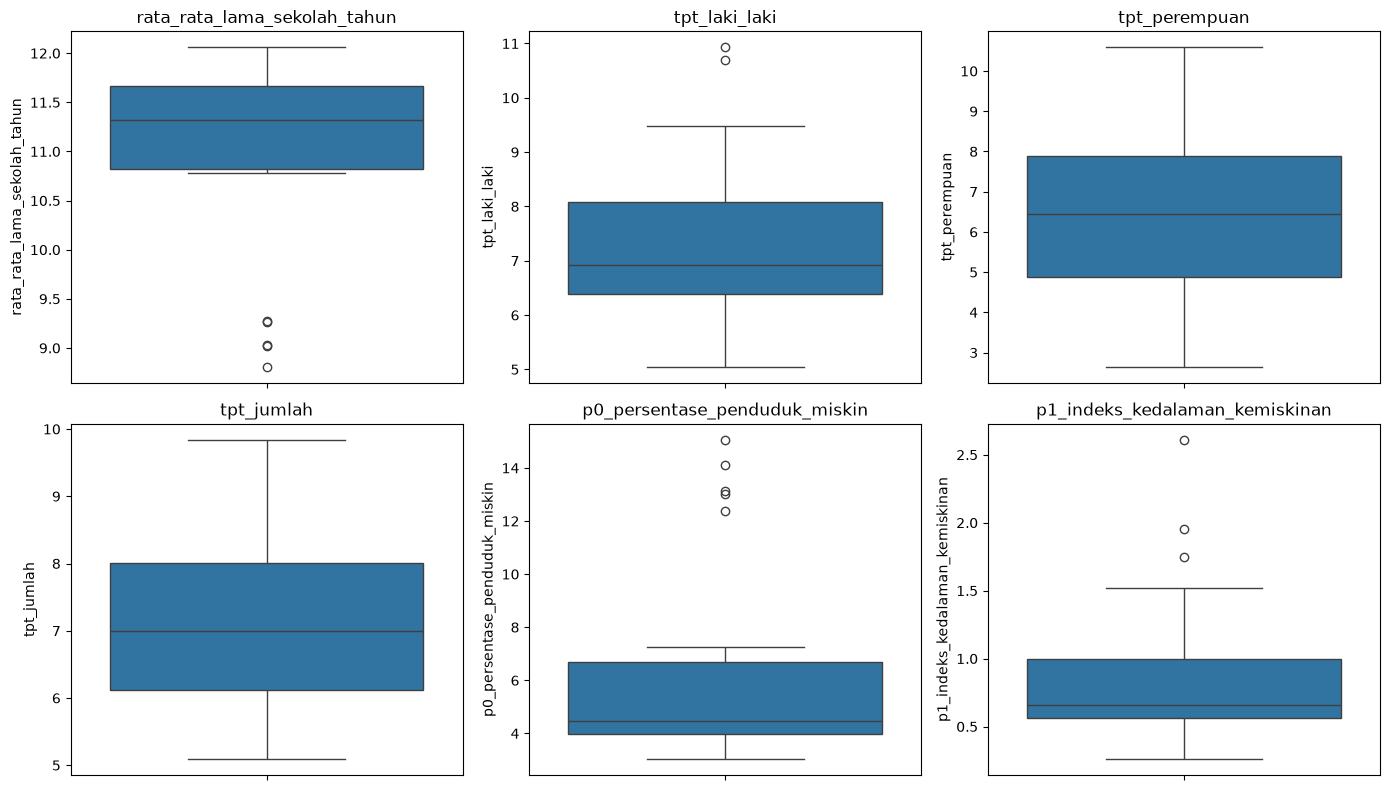

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, kolom):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [14]:
# Deteksi outlier dengan aturan IQR
for col in kolom:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[col] < bawah) | (df[col] > atas)]
    print(f"{col}: batas {bawah:.2f} s.d. {atas:.2f}, jumlah outlier = {len(out)}")
    print(out[["tahun", "wilayah", col]].to_string(index=False))
    print()

rata_rata_lama_sekolah_tahun: batas 9.56 s.d. 12.93, jumlah outlier = 5
 tahun          wilayah  rata_rata_lama_sekolah_tahun
  2021 Kepulauan Seribu                          8.81
  2022 Kepulauan Seribu                          9.02
  2023 Kepulauan Seribu                          9.03
  2024 Kepulauan Seribu                          9.26
  2025 Kepulauan Seribu                          9.27

tpt_laki_laki: batas 3.85 s.d. 10.64, jumlah outlier = 2
 tahun          wilayah  tpt_laki_laki
  2021 Kepulauan Seribu          10.69
  2021    Jakarta Utara          10.93

tpt_perempuan: batas 0.33 s.d. 12.45, jumlah outlier = 0
Empty DataFrame
Columns: [tahun, wilayah, tpt_perempuan]
Index: []

tpt_jumlah: batas 3.26 s.d. 10.86, jumlah outlier = 0
Empty DataFrame
Columns: [tahun, wilayah, tpt_jumlah]
Index: []

p0_persentase_penduduk_miskin: batas -0.10 s.d. 10.77, jumlah outlier = 5
 tahun          wilayah  p0_persentase_penduduk_miskin
  2021 Kepulauan Seribu                          15.06


In [15]:
pivot_p0 = df.pivot(index="wilayah", columns="tahun", values="p0_persentase_penduduk_miskin")
pivot_p0["selisih_2021_2025"] = pivot_p0[2025] - pivot_p0[2021]
pivot_p0.round(2)

tahun,2021,2022,2023,2024,2025,selisih_2021_2025
wilayah,,,,,,
Jakarta Barat,4.31,4.22,4.09,3.94,3.91,-0.40
Jakarta Pusat,4.94,4.90,4.68,4.63,4.70,-0.24
Jakarta Selatan,3.56,3.52,3.10,3.03,3.23,-0.33
Jakarta Timur,4.28,4.30,4.20,4.09,3.94,-0.34
Jakarta Utara,7.24,7.24,6.78,6.44,6.33,-0.91
Kepulauan Seribu,15.06,14.11,13.13,13.03,12.37,-2.69


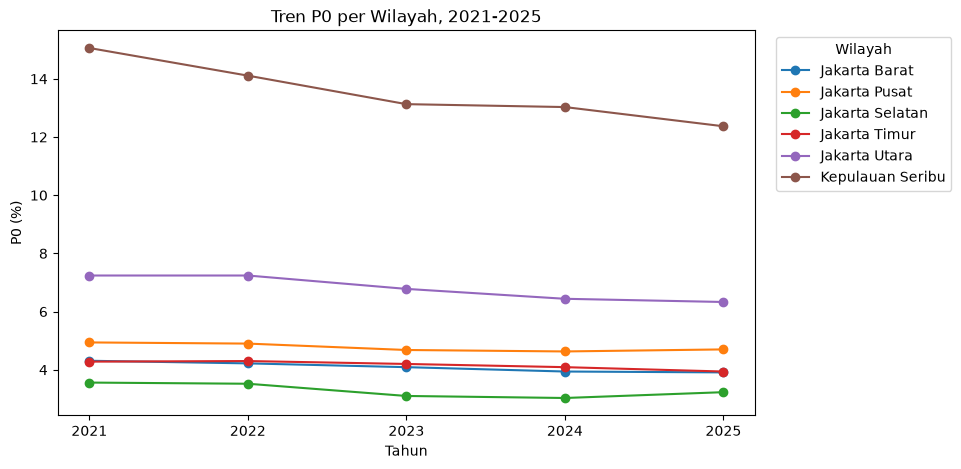

In [20]:
tren_p0 = pivot_p0.drop(columns="selisih_2021_2025").T

plt.figure(figsize=(9, 5))
for wilayah in tren_p0.columns:
    plt.plot(tren_p0.index.astype(int), tren_p0[wilayah], marker="o", label=wilayah)

plt.title("Tren P0 per Wilayah, 2021-2025")
plt.xlabel("Tahun")
plt.ylabel("P0 (%)")
plt.xticks(range(2021, 2026))
plt.legend(title="Wilayah", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [21]:
korelasi_p = df[kolom].corr(method="pearson")
korelasi_p.round(2)

,rata_rata_lama_sekolah_tahun,tpt_laki_laki,tpt_perempuan,tpt_jumlah,p0_persentase_penduduk_miskin,p1_indeks_kedalaman_kemiskinan
rata_rata_lama_sekolah_tahun,1.00,-0.35,-0.42,-0.54,-0.96,-0.86
tpt_laki_laki,-0.35,1.00,0.04,0.77,0.35,0.38
tpt_perempuan,-0.42,0.04,1.00,0.67,0.41,0.20
tpt_jumlah,-0.54,0.77,0.67,1.00,0.53,0.42
p0_persentase_penduduk_miskin,-0.96,0.35,0.41,0.53,1.00,0.89
p1_indeks_kedalaman_kemiskinan,-0.86,0.38,0.20,0.42,0.89,1.00


In [22]:
korelasi_s = df[kolom].corr(method="spearman")
korelasi_s.round(2)

,rata_rata_lama_sekolah_tahun,tpt_laki_laki,tpt_perempuan,tpt_jumlah,p0_persentase_penduduk_miskin,p1_indeks_kedalaman_kemiskinan
rata_rata_lama_sekolah_tahun,1.00,-0.36,-0.34,-0.55,-0.82,-0.73
tpt_laki_laki,-0.36,1.00,0.02,0.73,0.39,0.23
tpt_perempuan,-0.34,0.02,1.00,0.65,0.39,0.18
tpt_jumlah,-0.55,0.73,0.65,1.00,0.62,0.35
p0_persentase_penduduk_miskin,-0.82,0.39,0.39,0.62,1.00,0.76
p1_indeks_kedalaman_kemiskinan,-0.73,0.23,0.18,0.35,0.76,1.00


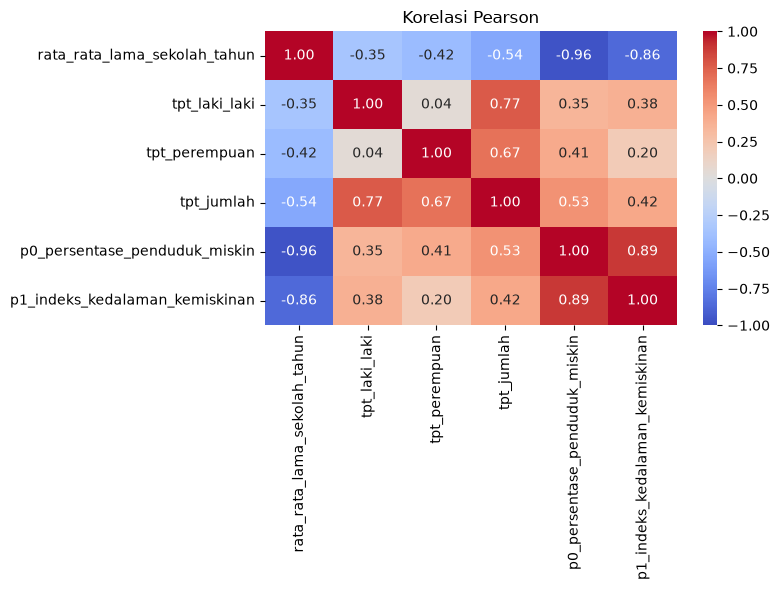

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(korelasi_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Pearson")
plt.tight_layout()
plt.show()

In [24]:
df_tanpa_ks = df[df["wilayah"] != "Kepulauan Seribu"]
print(df_tanpa_ks.shape)
df_tanpa_ks[kolom].corr(method="pearson").round(2)

(25, 8)


,rata_rata_lama_sekolah_tahun,tpt_laki_laki,tpt_perempuan,tpt_jumlah,p0_persentase_penduduk_miskin,p1_indeks_kedalaman_kemiskinan
rata_rata_lama_sekolah_tahun,1.00,-0.43,-0.21,-0.43,-0.74,-0.63
tpt_laki_laki,-0.43,1.00,0.19,0.82,0.43,0.22
tpt_perempuan,-0.21,0.19,1.00,0.72,0.25,0.01
tpt_jumlah,-0.43,0.82,0.72,1.00,0.45,0.17
p0_persentase_penduduk_miskin,-0.74,0.43,0.25,0.45,1.00,0.77
p1_indeks_kedalaman_kemiskinan,-0.63,0.22,0.01,0.17,0.77,1.00


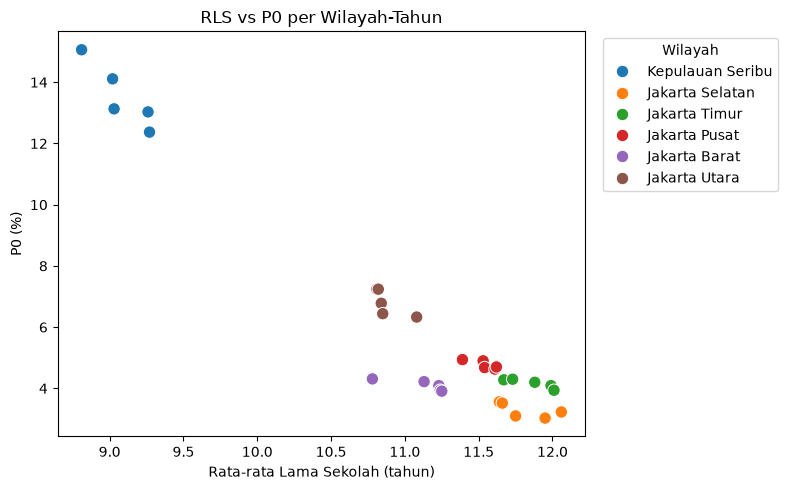

In [32]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="rata_rata_lama_sekolah_tahun",
    y="p0_persentase_penduduk_miskin",
    hue="wilayah",
    s=80,
)
plt.title("RLS vs P0 per Wilayah-Tahun")
plt.xlabel("Rata-rata Lama Sekolah (tahun)")
plt.ylabel("P0 (%)")
plt.legend(title="Wilayah", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [33]:
def gambar_tren(kolom_nama, judul, label_y):
    pivot = df.pivot(index="wilayah", columns="tahun", values=kolom_nama).T
    plt.figure(figsize=(9, 5))
    for wilayah in pivot.columns:
        plt.plot(pivot.index.astype(int), pivot[wilayah], marker="o", label=wilayah)
    plt.title(judul)
    plt.xlabel("Tahun")
    plt.ylabel(label_y)
    plt.xticks(range(2021, 2026))
    plt.legend(title="Wilayah", loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

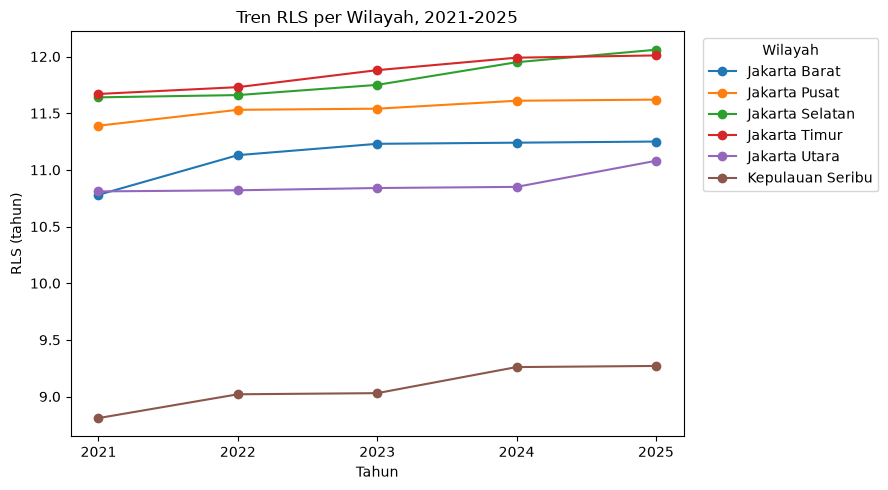

In [30]:
gambar_tren("rata_rata_lama_sekolah_tahun", "Tren RLS per Wilayah, 2021-2025", "RLS (tahun)")

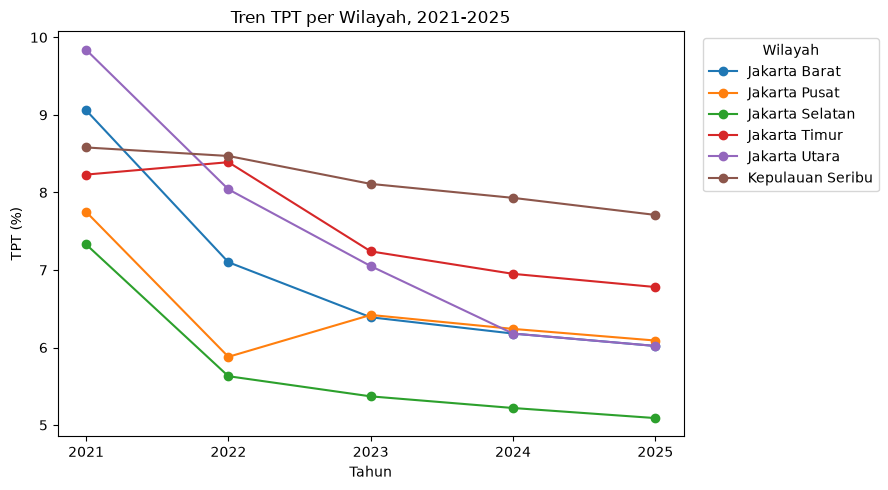

In [36]:
gambar_tren("tpt_jumlah", "Tren TPT per Wilayah, 2021-2025", "TPT (%)")

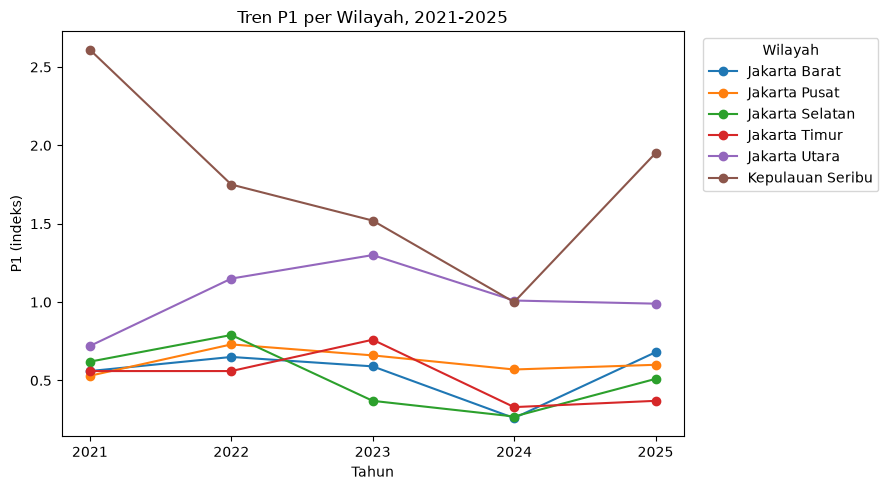

In [37]:
gambar_tren("p1_indeks_kedalaman_kemiskinan", "Tren P1 per Wilayah, 2021-2025", "P1 (indeks)")